# ML Assignment 2 - Breast Cancer Classification + Streamlit Deployment
**Programme:** M.Tech (AIML) - Machine Learning

## a. Problem Statement
Classify a breast tumour as **malignant (cancerous)** or **benign (non-cancerous)** from measurements of cell
nuclei computed from a digitised image of a fine needle aspirate (FNA) of the breast mass.

* **Type:** Binary classification
* **Target (`Target`)**: `1` = Malignant, `0` = Benign
* Early and accurate diagnosis matters, so besides Accuracy we pay special attention to **Recall** (not missing
  malignant cases), Precision, AUC and MCC.

Five classifiers are trained on the same data and compared using six metrics:
Accuracy, AUC, Precision, Recall, F1 and MCC.

## Step 1 - Import libraries

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                     # fixed seed -> reproducible results
os.makedirs("model", exist_ok=True)   # folder where trained models will be saved

## Step 2 - Load the dataset (b. Dataset description)
* **Source:** UCI Machine Learning Repository - *Breast Cancer Wisconsin (Diagnostic)* (WDBC)
* **Instances:** 569 patients (minimum required: 500)
* **Features:** 30 real-valued features (minimum required: 12). Ten nuclear characteristics are computed for each
  image: radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry and
  fractal dimension. For each one the **mean**, **standard error (se)** and **worst** (mean of the three largest
  values) are given -> 10 x 3 = 30 features.
* **Classes:** 357 Benign (B) and 212 Malignant (M)

The raw UCI file `wdbc.data` has no header row, so column names were added (taken from `wdbc.names`) and the
file was saved as `breast_cancer_wdbc.csv`.

In [2]:
df = pd.read_csv("breast_cancer_wdbc.csv")
print("Shape:", df.shape)
df.head()

Shape: (569, 32)


,id,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Step 3 - Exploratory checks

Missing values: 0
Duplicate patient IDs: 0
diagnosis
B    357
M    212
Name: count, dtype: int64


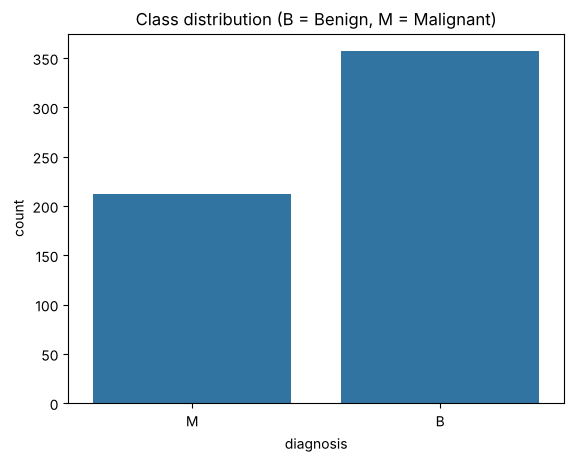

In [3]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate patient IDs:", df["id"].duplicated().sum())
print(df["diagnosis"].value_counts())

sns.countplot(x="diagnosis", data=df)
plt.title("Class distribution (B = Benign, M = Malignant)")
plt.show()

In [4]:
# Summary statistics of a few features - note how different the scales are (area vs smoothness)
df[["mean_radius", "mean_area", "mean_smoothness", "worst_concave_points"]].describe().round(3)

,mean_radius,mean_area,mean_smoothness,worst_concave_points
count,569.000,569.000,569.000,569.000
mean,14.127,654.889,0.096,0.115
std,3.524,351.914,0.014,0.066
min,6.981,143.500,0.053,0.000
25%,11.700,420.300,0.086,0.065
50%,13.370,551.100,0.096,0.100
75%,15.780,782.700,0.105,0.161
max,28.110,2501.000,0.163,0.291


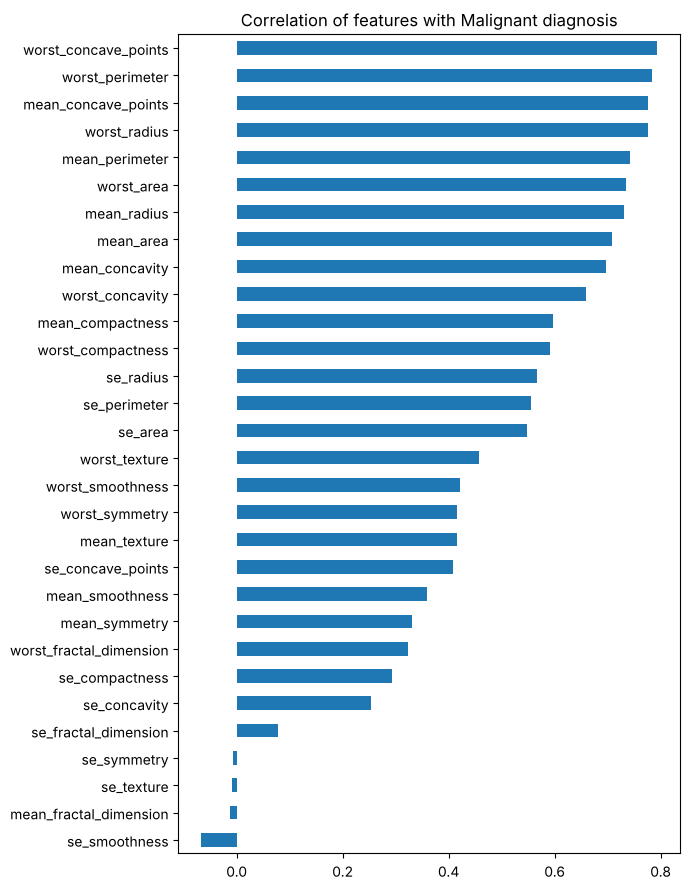

In [5]:
# Correlation of every feature with the diagnosis (M = 1) - shows which features separate the classes best
corr = df.drop(columns=["id", "diagnosis"]).corrwith((df["diagnosis"] == "M").astype(int)).sort_values()
corr.plot(kind="barh", figsize=(7, 9))
plt.title("Correlation of features with Malignant diagnosis")
plt.tight_layout()
plt.show()

## Step 4 - Create the target variable and select features
* `diagnosis` is text (B/M), so it is converted to numbers: **M -> 1 (positive class), B -> 0**
* `id` is only a patient identifier and has no predictive meaning, so it is dropped

In [6]:
df["Target"] = (df["diagnosis"] == "M").astype(int)

feature_cols = [c for c in df.columns if c not in ["id", "diagnosis", "Target"]]
X = df[feature_cols]
y = df["Target"]
print("Number of features:", len(feature_cols))
print("Number of instances:", len(X))

Number of features: 30
Number of instances: 569


## Step 5 - Train / test split
Each row is an independent patient (not a time series), so a **random stratified split** is used:
80% training, 20% testing. `stratify=y` keeps the benign/malignant ratio the same in both parts.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Malignant share - train: %.3f, test: %.3f" % (y_train.mean(), y_test.mean()))

# Save the test data (features + Target) - this CSV is uploaded in the Streamlit app
test_data = X_test.copy()
test_data["Target"] = y_test.values
test_data.to_csv("test_data.csv", index=False)
print("test_data.csv saved")

Train: (455, 30)  Test: (114, 30)
Malignant share - train: 0.374, test: 0.368
test_data.csv saved


## Step 6 - Define the five models
Each model sits inside a scikit-learn **Pipeline** with a `StandardScaler`. Scaling matters here because the
features have very different ranges (e.g. area ~ 500-2500 while smoothness ~ 0.1), and Logistic Regression, KNN and
SVM are sensitive to that. The scaler is fitted on training data only and is saved inside the pipeline, so the
Streamlit app can predict on raw uploaded data without retraining.

In [8]:
def make_pipeline(clf):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("clf", clf),
    ])

models = {
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    # max_depth limits tree growth to reduce over-fitting
    "Decision Tree": make_pipeline(DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)),
    "KNN": make_pipeline(KNeighborsClassifier(n_neighbors=5)),
    "Naive Bayes": make_pipeline(GaussianNB()),
    # probability=True is needed to compute the AUC score
    "Support Vector Machine": make_pipeline(SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
}

## Step 7 - Train all models, evaluate on the test data and save them

In [9]:
results = []
predictions = {}   # store predictions for the confusion matrices later
probabilities = {} # store probabilities for the ROC curves later

for name, pipe in models.items():
    pipe.fit(X_train, y_train)                      # train

    y_pred = pipe.predict(X_test)                   # class prediction (0/1)
    y_prob = pipe.predict_proba(X_test)[:, 1]       # probability of class 1 (needed for AUC)
    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "ML Model Name": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "AUC":       roc_auc_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1":        f1_score(y_test, y_pred),
        "MCC":       matthews_corrcoef(y_test, y_pred),
    })

    # Save the trained pipeline, e.g. model/logistic_regression.joblib
    fname = "model/" + name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(pipe, fname)

# Save the feature list so the app knows which columns to expect
joblib.dump(feature_cols, "model/feature_cols.joblib")

results_df = pd.DataFrame(results).round(4)
results_df.to_csv("model_results.csv", index=False)
results_df

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9123,0.8770,0.9444,0.8095,0.8718,0.8113
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Naive Bayes,0.9211,0.9891,0.9231,0.8571,0.8889,0.8292
4,Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


## Step 8 - Confusion matrices and classification reports

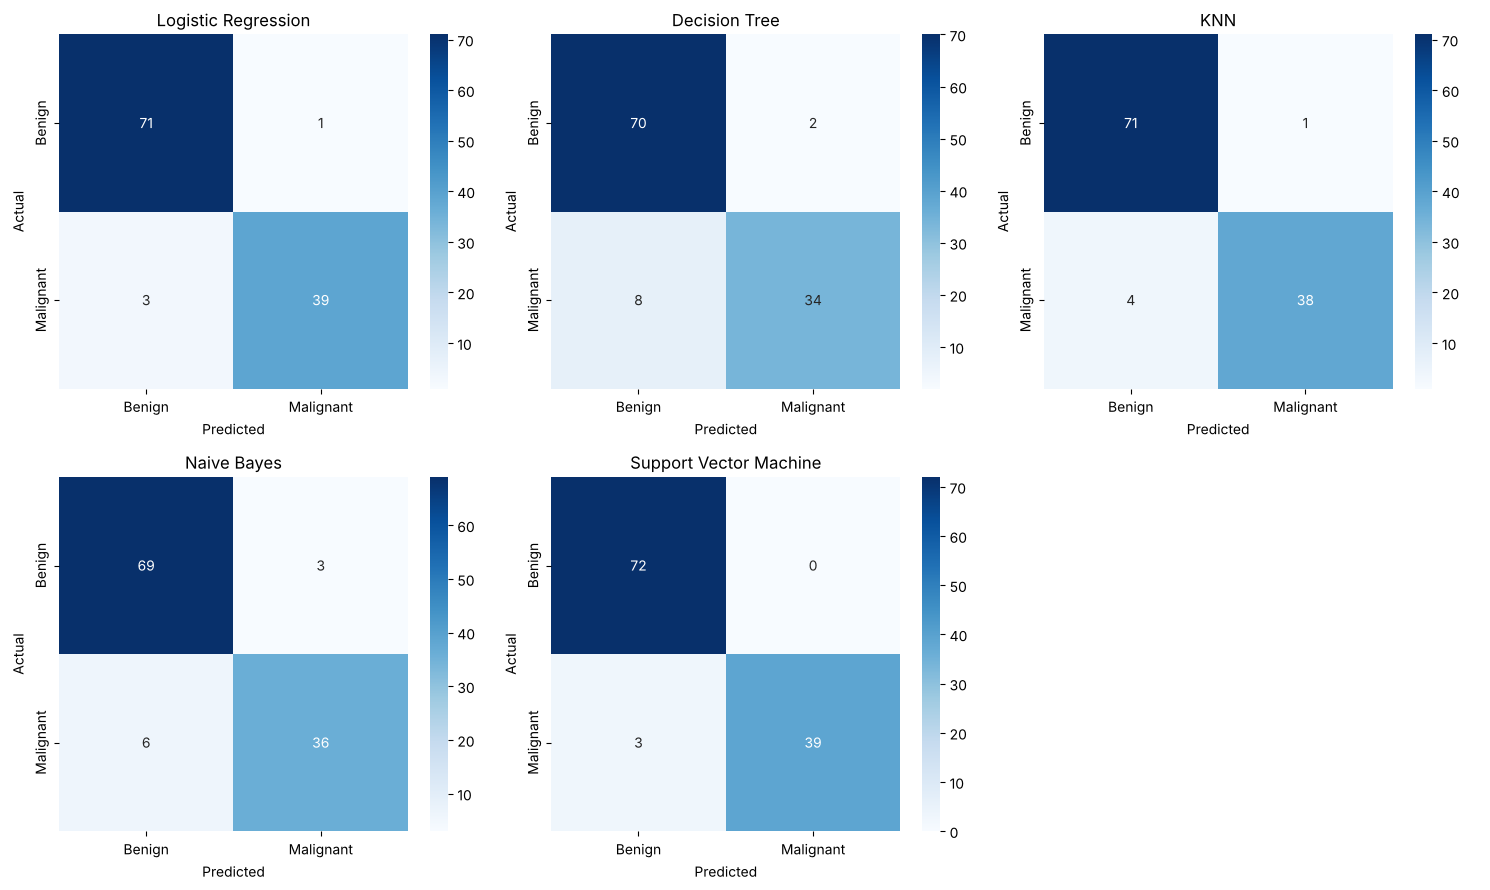

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

axes[-1].axis("off")   # 5 models, 6 slots -> hide the extra one
plt.tight_layout()
plt.show()

In [11]:
for name, y_pred in predictions.items():
    print("=" * 60)
    print(name)
    print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))

Logistic Regression
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

Decision Tree
              precision    recall  f1-score   support

      Benign       0.90      0.97      0.93        72
   Malignant       0.94      0.81      0.87        42

    accuracy                           0.91       114
   macro avg       0.92      0.89      0.90       114
weighted avg       0.91      0.91      0.91       114

KNN
              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97        72
   Malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96   

## Step 9 - ROC curves and metric comparison chart

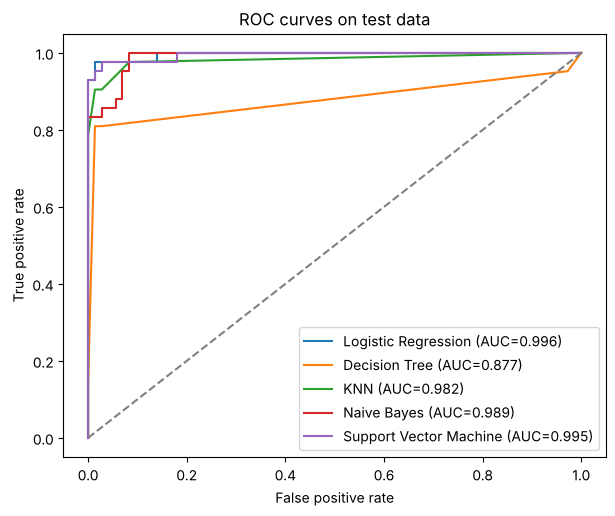

In [12]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(7, 5.5))
for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, y_prob):.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves on test data")
plt.legend(loc="lower right")
plt.show()

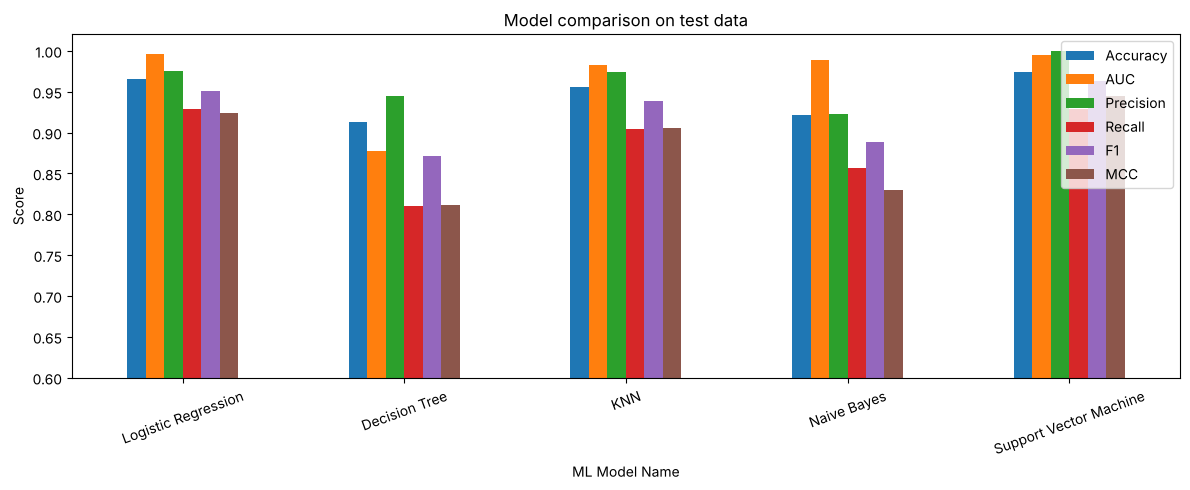

In [13]:
results_df.set_index("ML Model Name")[["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]].plot(
    kind="bar", figsize=(12, 5))
plt.title("Model comparison on test data")
plt.ylabel("Score")
plt.ylim(0.6, 1.02)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Step 10 - Cross-validation check (extra)
The test set has only 114 patients, so one lucky or unlucky split can change the scores noticeably.
A 5-fold stratified cross-validation on the full data gives a more stable picture of each model.

In [14]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipe in models.items():
    scores = cross_val_score(pipe, X, y, cv=skf, scoring="accuracy")
    cv_rows.append({"ML Model Name": name,
                    "CV Mean Accuracy": scores.mean().round(4),
                    "CV Std": scores.std().round(4)})
pd.DataFrame(cv_rows)

,ML Model Name,CV Mean Accuracy,CV Std
0,Logistic Regression,0.9737,0.0166
1,Decision Tree,0.9227,0.0295
2,KNN,0.9631,0.0179
3,Naive Bayes,0.9297,0.0199
4,Support Vector Machine,0.9772,0.0163


## Step 11 - Sanity check: reload a saved model
Confirms that a saved model gives the same predictions without retraining - exactly what the Streamlit app does.

In [15]:
loaded = joblib.load("model/support_vector_machine.joblib")
test_csv = pd.read_csv("test_data.csv")
pred_again = loaded.predict(test_csv[feature_cols])
print("Reloaded accuracy:", round(accuracy_score(test_csv["Target"], pred_again), 4))
print("Matches original:", np.array_equal(pred_again, predictions["Support Vector Machine"]))

Reloaded accuracy: 0.9737
Matches original: True


## Step 12 - Observations
*(Write your own observations here after running the notebook, using your numbers from the table above.
Guide: Which model has the highest AUC and MCC? Which one misses the most malignant tumours (look at the
false negatives in the confusion matrices / low recall)? Why might the Decision Tree be weaker than
Logistic Regression and SVM on this dataset?)*